In [1]:
import pandas as pd
import numpy as np

# Load cleaned dataset
df = pd.read_csv("GE_OE_Cleaned_Data.csv")
print(df)

             Timestamp 3) What is your gender?  \
0   8/19/2026 10:57:56                    Male   
1    8/30/2026 7:55:20                    Male   
2    8/30/2026 9:28:03                    Male   
3   8/30/2026 10:11:59                    Male   
4   8/30/2026 10:32:12                    Male   
..                 ...                     ...   
87   9/8/2026 21:23:20                    Male   
88   9/8/2026 22:21:36                    Male   
89   9/8/2026 23:52:38                    Male   
90   9/9/2026 12:02:56                    Male   
91   9/9/2026 12:19:46                  Female   

   4) Which course/program are you studying?  \
0                                       B.SC   
1                                       B.SC   
2                                       B.SC   
3                                       B.SC   
4                                       B.SC   
..                                       ...   
87                                       B.A   
88             

In [2]:
target_col2 = [
    col for col in df.columns
    if "affect your performance in core/main subjects" in col.lower()
][0]

print("Target question:", target_col2)
print("\nResponse Counts:")
print(df[target_col2].value_counts())

Target question:  14) Do  GE/OE   subjects affect your performance in core/main subjects?   

Response Counts:
 14) Do  GE/OE   subjects affect your performance in core/main subjects?   
Moderately       33
Slightly         20
Significantly    19
Not At All       18
Not Answered      2
Name: count, dtype: int64


In [3]:
df_ml2 = df[
    df[target_col2].notna() &
    (df[target_col2] != "Not Answered")
].copy()

print("Dataset Shape:", df_ml2.shape)
print("\nTarget Response Counts:")
print(df_ml2[target_col2].value_counts())

Dataset Shape: (90, 25)

Target Response Counts:
 14) Do  GE/OE   subjects affect your performance in core/main subjects?   
Moderately       33
Slightly         20
Significantly    19
Not At All       18
Name: count, dtype: int64


In [4]:
# Select the target
y = df_ml2[target_col2]

# Exclude the target and timestamp from input features
exclude_cols = [
    target_col2,
    "Timestamp"
]

X = df_ml2.drop(
    columns=exclude_cols,
    errors="ignore"
)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nInput Columns:")
print(X.columns.tolist())

Input Features Shape: (90, 23)
Target Shape: (90,)

Input Columns:
['3) What is your gender?', '4) Which course/program are you studying?', '5) Which branch/department are you from? ', '6) Which year are you currently studying?', '7) Are you aware that your college offers  GE/OE  Subject beyond the core curriculum', '8) Do you understand the purpose and objective behind offering these  GE/OE   subject ', '9)  How did you first learn about these  GE/OE  subjects?   ', ' 10) In your opinion,  GE/OE   subjects are:  ', '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [1) GE/OE subjects improve my communication skills]', '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [2) GE/OE subjects improve my technical/practical skills]', '11)  Rate the following on a 5-point scale (1 = Strongly Disagree, 5 = Strongly Agree) [3) GE/OE subjects contribute to my overall personality development]', '11)  Rate the following on a

In [5]:
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

# Encode input features
encoder2 = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_encoded2 = pd.DataFrame(
    encoder2.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Encode target
label_encoder2 = LabelEncoder()
y_encoded2 = label_encoder2.fit_transform(y)

print("Encoded Input Shape:", X_encoded2.shape)
print("Encoded Target Shape:", y_encoded2.shape)
print("\nTarget Classes:", label_encoder2.classes_)

Encoded Input Shape: (90, 23)
Encoded Target Shape: (90,)

Target Classes: ['Moderately' 'Not At All' 'Significantly' 'Slightly']


In [6]:
from sklearn.model_selection import train_test_split

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_encoded2,
    y_encoded2,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded2
)

print("Training data:", X_train2.shape)
print("Testing data:", X_test2.shape)

Training data: (72, 23)
Testing data: (18, 23)


In [7]:
from sklearn.tree import DecisionTreeClassifier

model2 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

# Train the model
model2.fit(X_train2, y_train2)

# Predict test responses
y_pred2 = model2.predict(X_test2)

print("Model training completed!")
print("Predictions:", label_encoder2.inverse_transform(y_pred2))

Model training completed!
Predictions: ['Not At All' 'Significantly' 'Not At All' 'Moderately' 'Significantly'
 'Moderately' 'Moderately' 'Moderately' 'Moderately' 'Not At All'
 'Significantly' 'Slightly' 'Moderately' 'Not At All' 'Moderately'
 'Moderately' 'Moderately' 'Slightly']


In [8]:
from sklearn.metrics import accuracy_score

accuracy2 = accuracy_score(y_test2, y_pred2)

print("Decision Tree Accuracy:", round(accuracy2 * 100, 2), "%")

Decision Tree Accuracy: 22.22 %


In [9]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test2,
    y_pred2,
    labels=range(len(label_encoder2.classes_)),
    target_names=label_encoder2.classes_,
    zero_division=0
))

               precision    recall  f1-score   support

   Moderately       0.33      0.43      0.38         7
   Not At All       0.25      0.33      0.29         3
Significantly       0.00      0.00      0.00         4
     Slightly       0.00      0.00      0.00         4

     accuracy                           0.22        18
    macro avg       0.15      0.19      0.17        18
 weighted avg       0.17      0.22      0.19        18



In [11]:
from sklearn.tree import DecisionTreeClassifier

models2 = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=3,
        random_state=42
    )
}

models2["Decision Tree"].fit(X_train2, y_train2)

print("Decision Tree model is ready!")

Decision Tree model is ready!


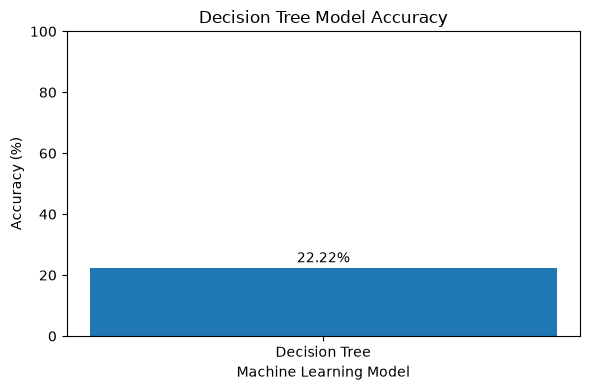

Decision Tree Accuracy: 22.22 %


In [15]:
import matplotlib.pyplot as plt

accuracy_percent = accuracy2 * 100

plt.figure(figsize=(6, 4))

plt.bar(
    ["Decision Tree"],
    [accuracy_percent],
    width=0.5
)

plt.title("Decision Tree Model Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.text(
    0,
    accuracy_percent + 2,
    f"{accuracy_percent:.2f}%",
    ha="center"
)

plt.tight_layout()
plt.show()

print("Decision Tree Accuracy:", round(accuracy_percent, 2), "%")

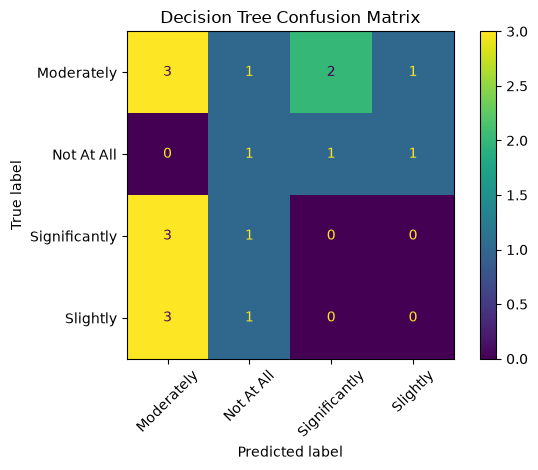

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test2, y_pred2)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder2.classes_
)

display.plot(xticks_rotation=45)
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

In [19]:
from IPython.display import display as show_table
import pandas as pd

results2 = pd.DataFrame({
    "Actual Response": label_encoder2.inverse_transform(y_test2),
    "Predicted Response": label_encoder2.inverse_transform(y_pred2)
})

show_table(results2)

,Actual Response,Predicted Response
0,Slightly,Not At All
1,Moderately,Significantly
2,Moderately,Not At All
3,Moderately,Moderately
4,Not At All,Significantly
5,Slightly,Moderately
6,Moderately,Moderately
7,Slightly,Moderately
8,Significantly,Moderately
9,Not At All,Not At All


In [21]:
from sklearn.tree import DecisionTreeClassifier

decision_tree2 = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
)

decision_tree2.fit(X_train2, y_train2)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [22]:
import joblib

joblib.dump(decision_tree2, "decision_tree_performance_model.pkl")
joblib.dump(encoder2, "input_encoder_performance.pkl")
joblib.dump(label_encoder2, "target_encoder_performance.pkl")

print("Model and encoders saved successfully!")

Model and encoders saved successfully!


In [28]:
from IPython.display import display as show_table

show_table(comparison_df2)

,Model,Accuracy (%)
0,Decision Tree,22.22
1,Random Forest,27.78
2,SVM,38.89


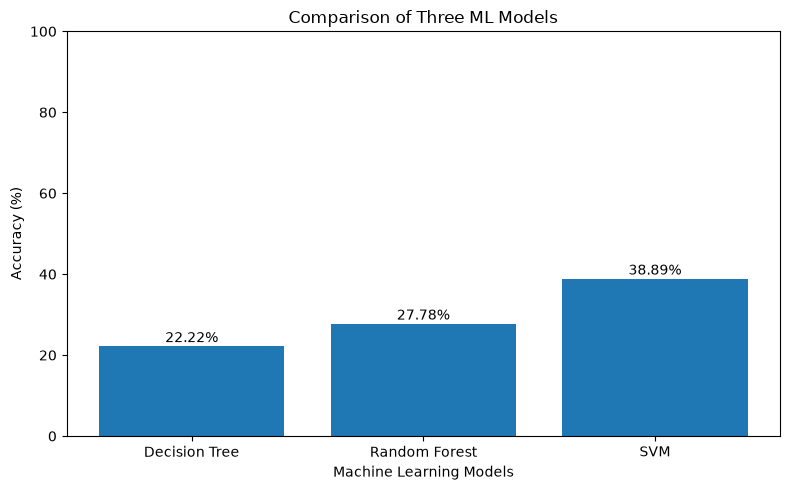

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    comparison_df2["Model"],
    comparison_df2["Accuracy (%)"]
)

plt.title("Comparison of Three ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()